# Week 5 (Unit 4) lab: Multiprocessing in Python

## Introduction

In this exercise, we are exploring the multiprocessing capabilities of Python to support the concepts of Processes, Process Lifecycle and Concurrent Execution. Over the last few weeks we've examined the time complexity of several different algorithms for sorting and matrix multiplication. To interrogate their behaviour, we instantiated the algorithm `N` times and were evaluating these _sequentially_, calculating the mean running time and standard deviation and examining how the dependent variable (time) changes as we linearly increase some independent variable (size of list or matrix). 

Fundamentally, this approach is going to be quite slow, since it's only leveraging a single available CPU core. For example, running 100 repeats sequentially of a product between two 250x250 square matrixes can take quite a long time. But we might have multiple CPU cores available to us, and we can leverage these by creating multiple worker processes to get results much faster. But we have to be careful, if we do this incorrectly, we will add noise to our results making them much less reliable and/or harder to interpret.

Today's lab provides you with both the tools and the intutition for how to find the critical threshold that maximises use of the resources available to you on any given machine (this approach is scalable beyond a single machine). You are tasked with running a `core_investigation` to find the critical threshold for the machine you are working on (i.e. that doesn't add noise to the running time of an algorithm). You are provided with an arbitrary algorithm, contained in `defs.py` - the function `work_that_CPU` - and we want to minimise the amount of time it takes to run `N` instantiations of the algorithm, while keeping the amount of work within each instantiation fixed.

You should empirically demonstrate what the optimal number of processes is and _explain why_. Think about what is going on within the machine. Why would results be unreliable when we've breached the critical threshold?

Once you have completed this, you are then tasked with splitting up the resources you do have available in a way that will provide you with the best assessment of the performance of the algorithm in question.

## Exercises

First let's import what we need from the multiprocessing library, and *time*, for timing code.

In [1]:
from multiprocessing import Pool, cpu_count
import time
import os

The multiprocessing package supports the spawning of separate processes running your Python code. In the following code, we create the given number of processes. Note that these are operating system level processes with their own threads of control and address spaces.

Let's investigate how processes are mapped to cores. For this, we're going to create a worker function that executes a lot of instructions (CPU-Bound), and we're going to time how long it takes. 

This worker function must be placed in an auxiliary file, here *defs.py*. Take a look at this file, and then import it by running the cell below.

In [2]:
import defs

In defs, there is a function called *work_that_CPU*, which will generate some random numbers (to the amount specified by the input *num_loops*), and save the time taken to do this, as well as the name of the process that is executing it.  

Next we write a function that will run *work_that_CPU* a number of times (as specified by the input *num_processes*), with each run being given to a different process.

In [3]:
def core_investigation(num_processes,num_loops):
    """
    Spawns a pool of worker processes to execute `defs.work_that_CPU` concurrently.

    Parameters:
        num_processes (int): The number of separate OS processes to create in the pool.
        num_loops (int): The number of random-number iterations each process will execute.
    """
    # Build a list passing the same workload (`num_loops`) to each worker process
    inputs = [num_loops] * num_processes

    # Spawn a pool of `num_processes` OS-level worker (child) processes
    # Each has own Process Control Block (kernel) and isolated memory space (RAM)
    # `Pool` is a software abstraction, no hardware limits, create childs until OS runs out of RAM
    # Hardware has CPU cores (4-16 typical), once `num_processes` exceeds then hardware parallelism maxes out.
    # After, OS short-term scheduler uses rapid context switching (concurrency) (
    # This degrades performance through overhead time per switch and evict CPU cache data (not register which is checkpointed in PCB)
    pool_of_processes = Pool(processes=num_processes)

    # Distribute `defs.work_that_CPU` across the pool, mapping one input per process
    # Pool.map(func, iterable) expects a 1D iterable (scalar) to be used a function call
    # .map. is a task dispatcher, it hands out the to-do list (function + inputs) to idle workers. 
    # .map blocks (pauses) Jupyter notebook until every single worker finishes it task and reports back
    pool_of_processes.map(defs.work_that_CPU, inputs)

    # Prevent any more tasks from being submitted to the pool and clean up resources
    pool_of_processes.close()

**Distinction between `num_loops` and `num_process`:**
- **`num_loops` (Workload per task/Depth):** Controls how heavy each individual job is. It is the strength of the task that a single process work needs to complete. Increasing it should make a process take longer. 

- **`num_processes` (Scale of concurrency/Breadth):** Controls how many separate OS worker processes are created and given a copy of that job simultaneously. `.map` needs to allocate this many jobs to processes. 

---

Each of our processes will be mapped to a physical core. Starting from 1 process, the time taken for each process should remain roughly constant until we exceed the available number of cores (which could range from 4 to 16 depending on your machine).

In [4]:
print("Logical CPUs (os):", os.cpu_count())
print("Logical CPUs (multiprocessing):", cpu_count())

Logical CPUs (os): 10
Logical CPUs (multiprocessing): 10


To see this, play around with the number of processes (*num_processes*) and the amount of computation in each process (*num_loops*) below. Settle on a value for *num_loops* so that the execution of this for a single process takes around 1s to complete.

In [5]:
num_loops=30000000
num_processes=1
core_investigation(num_processes,num_loops)

# Get the run-times for each of the processes, print them out, and then delete the files that store these.
for filename in os.listdir('.'):
    if filename.startswith('TimedProcess'):
        with open(filename, 'r') as file:
            content = file.read()
            print(content)
        os.remove(filename)

If each process is mapped to a different core, then the time taken should remain roughly constant. If not, then execution time should increase. 

Now run this for all values of *num_processes* from 1 up to 20, and compute for each run the total amount of time taken to run all the processes. Plot a graph of number of processes executing *work_that_CPU* against total time taken.

Note: you do not now need to save to disk all the times taken for every process here, so comment out the lines that do this in *work_that_CPU* in *defs.py*. To keep track of progress just print every value of *num_processes* as you get to it.

Running with 1 process(es)...
Running with 2 process(es)...
Running with 3 process(es)...
Running with 4 process(es)...
Running with 5 process(es)...
Running with 6 process(es)...
Running with 7 process(es)...
Running with 8 process(es)...
Running with 9 process(es)...
Running with 10 process(es)...
Running with 11 process(es)...
Running with 12 process(es)...
Running with 13 process(es)...
Running with 14 process(es)...
Running with 15 process(es)...
Running with 16 process(es)...
Running with 17 process(es)...
Running with 18 process(es)...
Running with 19 process(es)...
Running with 20 process(es)...


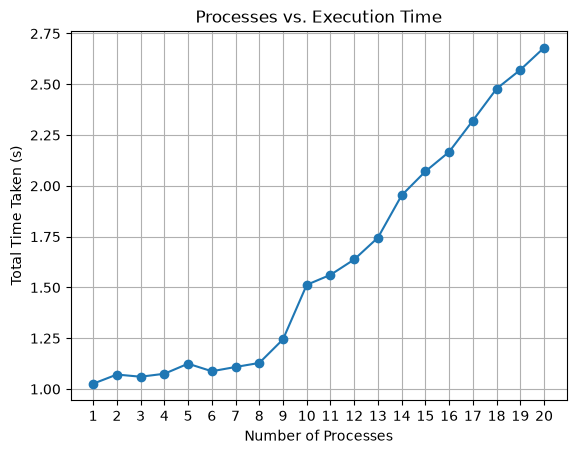

In [6]:
import matplotlib.pyplot as plt

process_counts = range(1, 21)
times = []

for num_processes in process_counts:
    print(f"Running with {num_processes} process(es)...")
    
    start = time.time()
    core_investigation(num_processes, num_loops)
    times.append(time.time() - start)

plt.plot(process_counts, times, marker='o')
plt.xlabel("Number of Processes")
plt.ylabel("Total Time Taken (s)")
plt.title("Processes vs. Execution Time")
plt.xticks(process_counts)
plt.grid(True)
plt.show()

You should notice that the total run-time is the same amount of time that it takes each process to run, even when there are more processes than cores available. Why do you think this is the case?

> _Answer_: The scheduler in your computer makes sure that all processes that you've created take turns at running, so they keep switching in and out of the CPU. The first process doesn't just hog the CPU until it is finished!

In [8]:
import importlib
importlib.reload(defs)

start = time.time()
core_investigation(20, num_loops)
total_time = time.time() - start

print(f"Total wall-clock time: {total_time:.4f} seconds\n")

for filename in sorted(os.listdir('.')):
    if filename.startswith('TimedProcess'):
        with open(filename, 'r') as file:
            print(file.read())
        os.remove(filename)

Total wall-clock time: 2.7228 seconds

SpawnPoolWorker-232 took 2.535120964050293 seconds
SpawnPoolWorker-233 took 2.0787270069122314 seconds
SpawnPoolWorker-234 took 2.2657032012939453 seconds
SpawnPoolWorker-235 took 2.433212995529175 seconds
SpawnPoolWorker-236 took 2.446043014526367 seconds
SpawnPoolWorker-237 took 2.2185442447662354 seconds
SpawnPoolWorker-238 took 2.503363847732544 seconds
SpawnPoolWorker-239 took 2.472254753112793 seconds
SpawnPoolWorker-240 took 2.322422981262207 seconds
SpawnPoolWorker-241 took 2.4385361671447754 seconds
SpawnPoolWorker-242 took 2.34798002243042 seconds
SpawnPoolWorker-243 took 2.0860350131988525 seconds
SpawnPoolWorker-244 took 2.4128541946411133 seconds
SpawnPoolWorker-245 took 2.3697919845581055 seconds
SpawnPoolWorker-246 took 2.0738413333892822 seconds
SpawnPoolWorker-247 took 2.5220091342926025 seconds
SpawnPoolWorker-248 took 2.394749164581299 seconds
SpawnPoolWorker-249 took 2.3958489894866943 seconds
SpawnPoolWorker-250 took 2.1707949

Now run *work_that_CPU* 20 times without using multiple processes, and time how long it takes. It should take a lot longer.

In [11]:
start = time.time()

for _ in range(20):
    core_investigation(1, num_loops)

print(f"Sequential time (20 runs): {time.time() - start:.4f}s")

Sequential time (20 runs): 20.4931s


Now, you're going to keep fixed at 20 the number of times that you're running `work_that_CPU`, and vary the number of concurrent processes that will do this job, from 1 up to 20. You'll then compute the run-times and plot them. That is, you'll plot number of concurrently running processes against time taken.

To do this, the first step is to write a modified version of the *core_investigation* function that now contains separate inputs for the number of times *work_that_CPU* will be run (*num_repeats*) and the number of processes that will run concurrently (*`num_processes`*). 

> Hint: You will do a certain number of rounds with *`work_that_CPU`* given to *`num_processes`* processes, until the number of repeats left to do is less than *`num_processes`*. Then you do one more round with the number of processes being the number of repeats you still need to run.

> Note: this question is misleading. It assumes that the function needs batching, i.e. if there are 20 repeats and only 5 processes, then a pre-computation is required to allocate 4 batches of 5 parelle runs. However, `.map` is a built in task allocator, meaning it maps N repeats to the M processors and queues the rest, when one process finishes another is allocated. 

In [ ]:
# def core_investigation(num_processes, num_repeats, num_loops):
#     """
#     Runs `defs.work_that_CPU` a total of `num_repeats` times using up to
#     `num_processes` concurrent worker processes per round.

#     Parameters:
#         num_processes (int): Maximum number of concurrent processes per round.
#         num_repeats (int): Total number of times `work_that_CPU` will be executed.
#         num_loops (int): Number of random-number iterations per `work_that_CPU` call.
#     """
#     full_rounds = num_repeats // num_processes
#     remainder = num_repeats % num_processes

#     # Run full rounds where every worker process receives one task
#     for _ in range(full_rounds):
#         inputs = [num_loops] * num_processes
#         pool = Pool(processes=num_processes)
#         pool.map(defs.work_that_CPU, inputs)
#         pool.close()

#     # If leftover repeats remain (< num_processes), run one final smaller round
#     if remainder > 0:
#         inputs = [num_loops] * remainder
#         pool = Pool(processes=remainder)
#         pool.map(defs.work_that_CPU, inputs)
#         pool.close()

In [13]:
def modified_core_investigation(num_processes,num_loops,num_repeats):
    """
    Spawns a pool of worker processes to execute `defs.work_that_CPU` concurrently.

    Parameters:
        num_processes (int): The number of separate OS processes to create in the pool.
        num_loops (int): The number of random-number iterations each process will execute.
        num_repeats (int): The total number of times `work_that_CPU` will be executed.
    """
    inputs = [num_loops] * num_repeats
    pool_of_processes = Pool(processes=num_processes)
    pool_of_processes.map(defs.work_that_CPU, inputs)
    pool_of_processes.close()

Running 20 repeats with 1 concurrent process(es)...
Running 20 repeats with 2 concurrent process(es)...
Running 20 repeats with 3 concurrent process(es)...
Running 20 repeats with 4 concurrent process(es)...
Running 20 repeats with 5 concurrent process(es)...
Running 20 repeats with 6 concurrent process(es)...
Running 20 repeats with 7 concurrent process(es)...
Running 20 repeats with 8 concurrent process(es)...
Running 20 repeats with 9 concurrent process(es)...
Running 20 repeats with 10 concurrent process(es)...
Running 20 repeats with 11 concurrent process(es)...
Running 20 repeats with 12 concurrent process(es)...
Running 20 repeats with 13 concurrent process(es)...
Running 20 repeats with 14 concurrent process(es)...
Running 20 repeats with 15 concurrent process(es)...
Running 20 repeats with 16 concurrent process(es)...
Running 20 repeats with 17 concurrent process(es)...
Running 20 repeats with 18 concurrent process(es)...
Running 20 repeats with 19 concurrent process(es)...
Ru

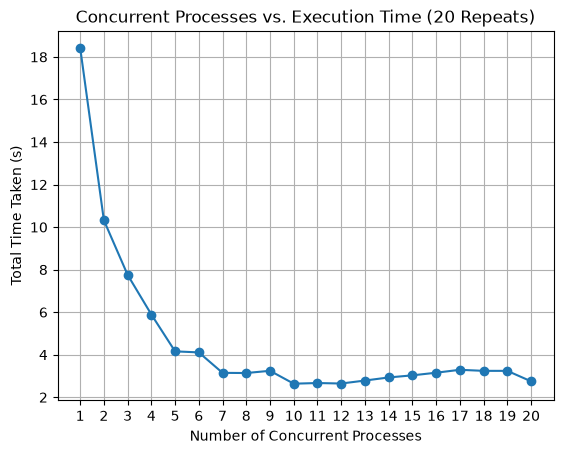

In [14]:
import matplotlib.pyplot as plt

num_repeats = 20
process_counts = range(1, 21)
times = []

for num_processes in process_counts:
    print(f"Running {num_repeats} repeats with {num_processes} concurrent process(es)...")
    
    start = time.time()
    modified_core_investigation(num_processes, num_loops, num_repeats)
    times.append(time.time() - start)

plt.plot(process_counts, times, marker='o')
plt.xlabel("Number of Concurrent Processes")
plt.ylabel("Total Time Taken (s)")
plt.title(f"Concurrent Processes vs. Execution Time ({num_repeats} Repeats)")
plt.xticks(process_counts)
plt.grid(True)
plt.show()

> Between 1 and 10 there is a sharpe inverse curve where the function is being allocated more proccesses/workers to complete the tasks, which at first drops the time exponentially as the cores divide up the tasks and run in parallel. After 10, the curve flattens out because all 10 physical cores are saturated, adding more software processes cannot execute the 20 jobs any faster. Any fluctutions are caused by overheads and machien variance. 

Now, compute the run-times and make the plot. Keep fixed at 20 the number of times that you're running *work_that_CPU*, and vary the number of concurrent processes that will do this job, from 1 up to 20. Compute the run-times and plot them. That is, plot number of concurrently running processes against time taken.

> Hint: Do not use lots of repeats in the *timeit* function. You don't want this to take too long. Also consider printing progress reports along the way so you know how long you're going to have to wait for output.

**Optional extension.** Repeat the above exercise running some other functions multiple times. Use a function that actually has some output (which will need to be sent back to the parent process, i.e. the rest of the Jupyter notebook). Do you always get speed up by parallelising? Play around with functions that take different lengths of time to run, and which return different quantities of data.

> This extension is import because OS processes do not share memory, each as its own isolated heap and stack. When one of the process workers computes something, returning it involves passing it to the parent process whichis the Jupyter Notebook. Python has to transfer over the data/bytes (pickling, pipe transfer, unpickling). If the functions returned data is vast then the passover can take longer than the computation itself. 

> Parallelization only speeds things up when Computation Time > Overhead.

> The reason we altered the original function to take 1 second is because super quick computations mean the overheads and act of context-switching take orders of magnitude longer than just running a simple for loop on 1 core.

> Linking back to this extension, if the ata returned is large (>500mb) the transfer to the parent process becomes a a single-core bottleneck

**Message Passing vs. Shared Memory:** Python's multiprocessing.Pool uses message passing (via OS pipes) to return values safely without race conditions, avoiding the need for manual mutex locks—but paying the performance price of copying data between isolated address spaces.

**Amdahl's Law:** Even when work is parallelized across 10 cores, the serial portion of the program (creating the pool, distributing inputs, and collecting/unpickling results in the single parent process) cannot be parallelized and caps your maximum possible speedup.